In [316]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

users = pd.read_csv("../data/users.csv")
marketing = pd.read_csv("../data/marketing_spend.csv")

In [317]:
users.shape

(70851, 10)

In [318]:
users.head()

,user_id,signup_date,channel,country,platform,activated_d7,trial_start_date,subscription_start_date,plan,subscription_end_date
0,U101247,2025-01-20,Organic,FR,iOS,0,NaN,NaN,NaN,NaN
1,U119636,2025-08-19,TikTok Ads,FR,Android,1,2025-08-20,NaN,NaN,NaN
2,U105849,2025-03-16,Organic,BE,Android,1,NaN,NaN,NaN,NaN
3,U147354,2026-02-11,TikTok Ads,FR,Android,1,2026-02-13,NaN,NaN,NaN
4,U118277,2025-08-06,Organic,FR,iOS,1,NaN,NaN,NaN,NaN


In [319]:
users.describe()

,activated_d7
count,70851.000000
mean,0.355648
std,0.478713
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [320]:
users.columns

Index(['user_id', 'signup_date', 'channel', 'country', 'platform',
       'activated_d7', 'trial_start_date', 'subscription_start_date', 'plan',
       'subscription_end_date'],
      dtype='str')

In [321]:
users.isna().sum()

user_id                        0
signup_date                    0
channel                        0
country                     1510
platform                       0
activated_d7                   0
trial_start_date           51412
subscription_start_date    63695
plan                       63695
subscription_end_date      68218
dtype: int64

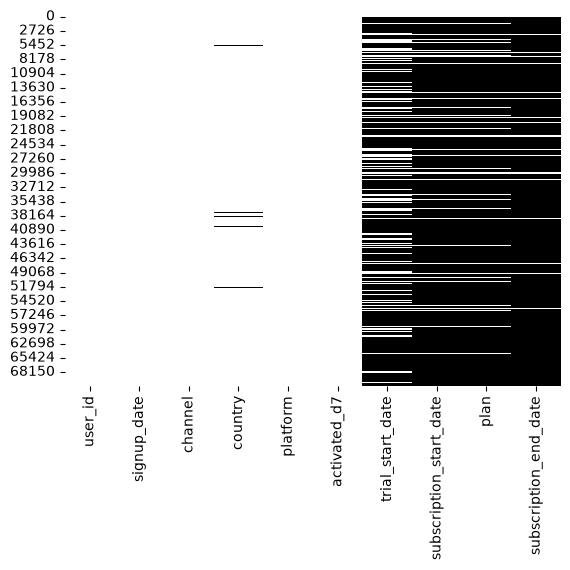

In [322]:
sns.heatmap(users.isna(), cbar=False, cmap='binary')
plt.show()

In [323]:
users["subscription_start_date"].isna().sum()

np.int64(63695)

Cleaning the data from dublicated values

In [324]:
users.duplicated().sum()

np.int64(562)

In [ ]:
users.drop_duplicates(inplace=True)

/var/folders/kp/sltrcngd1_j5f8ssgy8kfj8m0000gn/T/ipykernel_59166/1385514362.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  users.drop_duplicates(inplace=True)


In [326]:
users.shape

(70289, 10)

channel dublicated values

In [327]:
users["channel"].value_counts()

channel
TikTok Ads      17407
Meta Ads        16462
Organic         10100
Google Ads       8309
Influencers      7705
tiktok           3035
Referral         2925
meta_ads         1471
Facebook Ads     1427
google_ads       1403
internal           45
Name: count, dtype: int64

In [328]:
mapping = {
    "Facebook Ads": "Facebook",
    "meta_ads": "Meta",
    "Meta Ads": "Meta",
    "google_ads": "Google",
    "Google Ads": "Google",
    "TikTok Ads": "TikTok",
    "tiktok": "TikTok",
    "Organic": "Organic",
    "Influencers": "Influencers",
    "Referral": "Referral",
    "internal": "Internal"
}

In [329]:
users["channel"] = users["channel"].str.strip().replace(mapping)


Dealing with mixed date formats